## Classificação da condição periodontal a partir do microbioma oral utilizando aprendizado de máquina

**Objetivo:** investigar se os dados do microbioma oral podem ajudar a distinguir participantes sem periodontite daqueles com periodontite e, adicionalmente, diferenciar as categorias de gravidade por meio de algoritmos de aprendizado de máquina.  
**Hipótese:** a composição do microbioma oral contém informação útil para discriminar tanto a presença/ausência da periodontite quanto as categorias periodontais, embora a capacidade preditiva possa variar entre os desfechos, as classes e os algoritmos.

O fluxograma abaixo representa o fluxo de análise. Os desfechos binário e multiclasse serão investigados em paralelo nas etapas exploratórias e na modelagem, com resultados apresentados separadamente.

## 0. Preparação do ambiente

**Rode esta célula antes de qualquer outra.** Ela funciona tanto no Google Colab quanto no computador:

- **No Colab:** baixa o código do projeto do repositório e instala as bibliotecas nas versões exatas usadas no trabalho. Na primeira vez, a sessão **reinicia sozinha** depois da instalação (aparece um aviso de que a sessão travou, é esperado): quando reconectar, rode esta mesma célula de novo.
- **No computador:** não instala nada (o ambiente já foi criado com `uv sync`, veja o README).

Nos dois casos, ela baixa os dados do NHANES direto do site do CDC para a pasta `datasets/`. Os arquivos que já estiverem lá e íntegros não são baixados de novo.

In [1]:
import os
import sys

# Endereço do repositório do projeto (usado só no Colab).
URL_REPOSITORIO = "https://github.com/dpontejs/periodontite-microbioma-ml.git"

if "google.colab" in sys.modules:
    # 1) Baixa o código do projeto (só na primeira vez).
    if not os.path.exists("baixar_dados.py"):
        if not os.path.exists("periodontite-microbioma-ml"):
            if not URL_REPOSITORIO:
                raise RuntimeError("Preencha URL_REPOSITORIO no início desta célula.")
            !git clone -q {URL_REPOSITORIO} periodontite-microbioma-ml
        %cd periodontite-microbioma-ml

    # 2) Instala as bibliotecas nas versões do projeto e reinicia a sessão
    #    (só na primeira vez; na segunda execução esta parte é pulada).
    if not os.path.exists(".ambiente_instalado"):
        !command -v uv > /dev/null || pip install -q uv
        !uv pip install -q --system -r requirements.txt
        open(".ambiente_instalado", "w").close()
        print("Bibliotecas instaladas. A sessão vai reiniciar agora.")
        print("Quando o Colab reconectar, rode ESTA MESMA CÉLULA de novo.")
        os.kill(os.getpid(), 9)

# 3) Baixa os dados do NHANES para a pasta datasets/.
from baixar_dados import baixar

baixar()

ok       ALQ_F.xpt
ok       ALQ_G.xpt
ok       BPQ_F.xpt
ok       BPQ_G.xpt
ok       DEMO_F.xpt
ok       DEMO_G.xpt
ok       DIQ_F.xpt
ok       DIQ_G.xpt
ok       MCQ_F.xpt
ok       MCQ_G.xpt
ok       OHXPER_F.xpt
ok       OHXPER_G.xpt
ok       PAQ_F.xpt
ok       PAQ_G.xpt
ok       dada2rsv-genus-count.txt
ok       dada2rsv-genus-relative.txt
ok       dada2rsv-taxonomy-annotate.txt
Pronto: 17 arquivos em /home/diegoponte/mlbioinfo/periodontite-microbioma-ml/datasets


[]

## 1. Obtenção e carregamento inicial dos dados

O NHANES (*National Health and Nutrition Examination Survey*) é um programa de avaliação da saúde e nutrição da população dos Estados Unidos, que combina entrevistas, exames físicos e análises laboratoriais.

Para o projeto, estamos interessados nos dados do microbioma oral, obtidos por meio de amostras de enxágue bucal (oral rinse samples). O processamento dessas amostras envolveu técnicas de biologia molecular e bioinformática.

De maneira simplificada, o fluxo experimental e computacional foi:
1. Coleta das amostras de enxágue bucal.
2. Extração do DNA microbiano.
3. Amplificação do gene 16S rRNA por PCR.
4. Sequenciamento dos amplicons utilizando a plataforma Illumina HiSeq 2500 (região V4).
5. Processamento bioinformático das sequências com DADA2.
6. Atribuição taxonômica utilizando o banco de dados SILVA.
7. Geração de tabelas de contagens e abundâncias relativas em diferentes níveis taxonômicos.

![fluxograma_rna_seq](images/fluxograma_rna_seq.jpeg)

**Alguns conceitos importantes**

**O que é o gene 16S rRNA e por que ele foi utilizado?**
- O gene 16S rRNA é um marcador molecular amplamente utilizado para identificar e caracterizar bactérias e arqueias. Ele apresenta regiões relativamente conservadas, que permitem a amplificação por primers, e regiões variáveis, que fornecem informações úteis para diferenciar grupos taxonômicos.Portanto, o sequenciamento dessa região permite caracterizar parcialmente a composição taxonômica da comunidade microbiana presente nas amostras.

---

**E o que é DADA2?**
- O DADA2 é um pipeline de bioinformática que modela e corrige erros de sequenciamento, permitindo inferir Amplicon Sequence Variants (ASVs).
Uma ASV representa uma sequência de DNA identificada após o processamento e a correção de erros. Isso permite distinguir sequências que diferem até mesmo por um único nucleotídeo.
Posteriormente, essas sequências recebem classificações taxonômicas pelo banco de dados SILVA versão 123.

**Tabela RSV**
- Tabela sem a sequência SV1032, identificada como um táxon não bacteriano associado a um agrupamento indesejado nas análises de diversidade beta. A presença da sequência em questão gerava agrupamentos anômalos e artificiais.

---

**Difersidades**

- Alpha: é uma matriz onde cada coluna representa uma métrica de diversidade bacteriana (índices de Shannon, Simpson, ASVs observadas...) de forma que cada participante tenha um número que represente a diversidade microbiológica encontrada nele;
- Beta: é uma matriz quadrada de pacientes x pacientes onde a comparação de diversidade é feita entre todoss os participantes.

---

Nesta etapa, carregamos a tabela pública de contagens brutas dos gêneros microbianos do ciclo 2009-2012.

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Localiza os arquivos tanto na pasta "datasets" (estrutura usual do Colab)
# quanto no diretório de trabalho ou em /mnt/data (ambiente local).
_candidatos_dados = [Path("datasets"), Path("."), Path("/mnt/data")]
DATA_DIR = next(
    (p for p in _candidatos_dados
     if (p / "dada2rsv-genus-count.txt").exists()),
    Path("datasets")
)
print("Diretório de dados utilizado:", DATA_DIR.resolve())

# carregando os dados de microbioma
df_microbiome = pd.read_csv(
    DATA_DIR / "dada2rsv-genus-count.txt", #RSV -> Sem SV1032 (táxon não bacteriano)
    sep="\t"
)

# Limpa possíveis espaços nos nomes das colunas
df_microbiome.columns = df_microbiome.columns.str.strip() # " SEQN " -> "SEQN"

print("Dimensões:", df_microbiome.shape)
display(df_microbiome.head())

print("\nTipos de dados:")
print(df_microbiome.dtypes.value_counts())

Diretório de dados utilizado: /home/diegoponte/mlbioinfo/periodontite-microbioma-ml/datasets


Dimensões: (9848, 1350)


,SEQN,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
0,57816.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,59605.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,56372.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,55484.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,55685.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,24,0,0,0,0,0



Tipos de dados:
int64      1349
float64       1
Name: count, dtype: int64


In [3]:
df_microbiome.describe()

,SEQN,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
count,9847.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,...,9848.000000,9848.0,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.0,9848.000000
mean,61919.993297,0.001219,0.136271,0.000305,0.005788,0.001320,0.005077,0.006093,0.003452,0.066714,...,0.052396,0.0,0.024878,0.006702,6.458367,0.014115,0.248477,0.057778,0.0,0.077579
std,5866.344665,0.102762,13.372855,0.030231,0.400146,0.095061,0.503844,0.575174,0.235880,5.854635,...,5.199669,0.0,2.282276,0.665074,127.110438,0.930893,8.340846,2.989745,0.0,7.658529
min,51624.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,56828.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
50%,62076.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
75%,66994.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
max,71916.000000,10.000000,1327.000000,3.000000,38.000000,8.000000,50.000000,57.000000,20.000000,579.000000,...,516.000000,0.0,226.000000,66.000000,8922.000000,69.000000,449.000000,233.000000,0.0,760.000000


## 2. Exploração e controle de qualidade da matriz de contagens

Vamos separar o identificador individual das variáveis microbianas, converter os valores para tipos numéricos e verificar valores ausentes, negativos, identificadores duplicados ou ausentes. A normalização ficará para a etapa de preparação do microbioma.


In [4]:
if "SEQN" not in df_microbiome.columns:
    raise ValueError(
        "A coluna SEQN não foi encontrada. "
        "Confira os nomes exibidos na célula anterior."
    )

# Transformar ID de float64 em Int64
df_microbiome["SEQN"] = pd.to_numeric(
    df_microbiome["SEQN"],
    errors="coerce" # transforma em NaN no caso de valores ausentes
).astype("Int64")

# Contabilizar IDs ausentes/inválidos antes da limpeza.
ids_invalidos = int(df_microbiome["SEQN"].isna().sum())
print("SEQN ausentes ou inválidos antes da limpeza:", ids_invalidos)

# Remover registros sem identificador, pois não podem ser integrados por SEQN.
df_microbiome = df_microbiome.dropna(subset=["SEQN"]).copy()

print("\nRegistros removidos por SEQN ausente/inválido:", ids_invalidos)
print("SEQN ausentes após a limpeza:", df_microbiome["SEQN"].isna().sum())
print("SEQN duplicados:", df_microbiome["SEQN"].duplicated().sum())

# Separa as colunas microbianas do identificador
microbial_cols = [
    col for col in df_microbiome.columns
    if col != "SEQN"
]

# criamos uma nova matriz contendo exclusivamente as contagens microbianas
X_counts = df_microbiome[microbial_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

print("\nNúmero de variáveis microbianas:", len(microbial_cols))
print("Valores ausentes na matriz:", X_counts.isna().sum().sum()) # 1sum coluna, 2sum total de células
print("Valores negativos:", (X_counts < 0).sum().sum())

display(X_counts)

SEQN ausentes ou inválidos antes da limpeza: 1



Registros removidos por SEQN ausente/inválido: 1
SEQN ausentes após a limpeza: 0
SEQN duplicados: 0

Número de variáveis microbianas: 1349
Valores ausentes na matriz: 0
Valores negativos: 0


,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,RSV_genus10,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,24,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9843,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9844,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9845,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9846,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
# Verifica a soma das contagens em cada participante
row_totals = X_counts.sum(axis=1)

print("Participantes com soma zero:", (row_totals == 0).sum())

# Exclui apenas amostras sem nenhuma contagem utilizável
valid_rows = row_totals > 0

# seleciona linhas cujos valores são válidos para a máscara row_total > 0
# apenas linhas cuja soma seja > 0 serão mantidas nos dois dataframes, resetando index para manter correspondência
df_microbiome = df_microbiome.loc[valid_rows].reset_index(drop=True)
X_counts = X_counts.loc[valid_rows].reset_index(drop=True)

df_microbiome.info()
print("-"*30)
X_counts.info()

Participantes com soma zero: 17


<class 'pandas.DataFrame'>
RangeIndex: 9830 entries, 0 to 9829
Columns: 1350 entries, SEQN to RSV_genus1349
dtypes: Int64(1), int64(1349)
memory usage: 101.3 MB
------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 9830 entries, 0 to 9829
Columns: 1349 entries, RSV_genus1 to RSV_genus1349
dtypes: int64(1349)
memory usage: 101.2 MB


Isso significa que encontramos 17 registros cujas 1.349 variáveis microbianas apresentam contagens com soma zero, na linha. Posteriormente, iremos normalizar cada contagem pelo total de contagens por linha. Um paciente cuja contagem tenha soma 0, não trará informações sobre a contagem bacteriana e causará erro pela divisão 0/0.

Saímos de 9.848 participantes (-17 com soma 0, -1 com SEQN ausente) para **9.830 participantes válidos**.

## 3. Preparação dos dados periodontais: carregamento dos exames

Vamos carregar os exames periodontais dos ciclos 2009–2010 e 2011–2012, verificar se as colunas correspondem e reunir os dois ciclos em uma única tabela. Em seguida, identificaremos os participantes com exame periodontal completo e sem exclusão médica do exame.


In [6]:
df_perio_f = pd.read_sas(
    DATA_DIR / "OHXPER_F.xpt",
    format="xport"
)

df_perio_g = pd.read_sas(
    DATA_DIR / "OHXPER_G.xpt",
    format="xport"
)

df_perio_f.columns = df_perio_f.columns.str.strip().str.upper()
df_perio_g.columns = df_perio_g.columns.str.strip().str.upper()

print("Dimensões do ciclo F:", df_perio_f.shape)
print("Dimensões do ciclo G:", df_perio_g.shape)

print("Colunas exclusivas do ciclo F:",
      sorted(set(df_perio_f.columns) - set(df_perio_g.columns)))

print("Colunas exclusivas do ciclo G:",
      sorted(set(df_perio_g.columns) - set(df_perio_f.columns)))

Dimensões do ciclo F: (5037, 508)
Dimensões do ciclo G: (4365, 508)
Colunas exclusivas do ciclo F: []
Colunas exclusivas do ciclo G: []


A comparação não identificou colunas exclusivas entre os ciclos F e G. Podemos, portanto, combinar os dois conjuntos e manter uma coluna que identifica o ciclo de origem.


In [7]:
df_perio_f["NHANES_CYCLE"] = "2009-2010"
df_perio_g["NHANES_CYCLE"] = "2011-2012"

df_perio_total = pd.concat(
    [df_perio_f, df_perio_g],
    ignore_index=True
)

df_perio_total["SEQN"] = pd.to_numeric(
    df_perio_total["SEQN"],
    errors="coerce"
).astype("Int64")

print("Dimensões combinadas:", df_perio_total.shape)
print("IDs ausentes:", df_perio_total["SEQN"].isna().sum())
print("IDs duplicados:", df_perio_total["SEQN"].duplicated().sum())

display(
    df_perio_total[
        ["SEQN", "OHDPDSTS", "OHDEXCLU", "NHANES_CYCLE"]
    ].sample(5)
)

Dimensões combinadas: (9402, 509)
IDs ausentes: 0
IDs duplicados: 0


,SEQN,OHDPDSTS,OHDEXCLU,NHANES_CYCLE
6258,64914,1.0,2.0,2011-2012
6981,66561,1.0,2.0,2011-2012
8343,69631,1.0,2.0,2011-2012
5732,63686,2.0,2.0,2011-2012
6983,66564,1.0,2.0,2011-2012


As variáveis de controle relevantes são:
- OHDPDSTS: o código 1 indica exame periodontal completo; 2, parcial; 3, não realizado.
- OHDEXCLU: o código 1 indica exclusão médica do exame e 2 indica que não houve essa exclusão.
Esses códigos podem ser conferidos nos codebooks oficiais dos ciclos.

https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/OHXPER_F.htm   
https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/OHXPER_G.htm

### 3.1 Seleção dos exames periodontais válidos

Para construir a classificação a partir das medidas clínicas, começamos pelos participantes com exame periodontal completo e sem exclusão por razões médicas. Essa restrição evita classificar como ausência de periodontite uma pessoa cujo exame não forneceu informação suficiente.


In [8]:
df_perio_total["OHDPDSTS"] = pd.to_numeric(
    df_perio_total["OHDPDSTS"],
    errors="coerce"
)

df_perio_total["OHDEXCLU"] = pd.to_numeric(
    df_perio_total["OHDEXCLU"],
    errors="coerce"
)

df_perio_complete = df_perio_total.loc[
    (df_perio_total["OHDPDSTS"] == 1) & # o exame periodontal foi completo
    (df_perio_total["OHDEXCLU"] == 2)   # o participante não foi excluído do exame por razões médicas
].copy()

print("Participantes com exame periodontal completo:",
      df_perio_complete.shape[0])

display(df_perio_complete.round(1))

Participantes com exame periodontal completo: 7770


,SEQN,OHDEXSTS,OHDPDSTS,OHDEXCLU,OHX02CJD,OHX02CJM,OHX02CJS,OHX02CJP,OHX02CJL,OHX02CJA,...,OHX31PCP,OHX31PCL,OHX31PCA,OHX31LAD,OHX31LAM,OHX31LAS,OHX31LAP,OHX31LAL,OHX31LAA,NHANES_CYCLE
0,51624,1.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,2009-2010
1,51628,1.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2009-2010
2,51630,1.0,1.0,2.0,1.0,0.0,1.0,1.0,0.0,1.0,...,2.0,2.0,4.0,1.0,2.0,3.0,1.0,2.0,3.0,2009-2010
3,51633,1.0,1.0,2.0,99.0,99.0,99.0,99.0,99.0,99.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2009-2010
4,51635,1.0,1.0,2.0,99.0,99.0,99.0,99.0,99.0,99.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2009-2010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9397,71904,1.0,1.0,2.0,0.0,0.0,0.0,0.0,-2.0,0.0,...,1.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,2011-2012
9398,71907,1.0,1.0,2.0,-4.0,-4.0,-2.0,0.0,0.0,0.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2011-2012
9399,71908,1.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2011-2012
9400,71912,1.0,1.0,2.0,99.0,-2.0,-1.0,-2.0,-4.0,-4.0,...,2.0,4.0,4.0,2.0,2.0,2.0,3.0,6.0,5.0,2011-2012


### 3.2 Critérios para a classificação periodontal

Usaremos a definição epidemiológica CDC - *Centers for Disease Control and Prevention* / AAP (*American Academy of Periodontology*) de vigilância da periodontite. Ela utiliza a perda de inserção clínica (clinical attachment loss, CAL ou AL) e a profundidade de sondagem periodontal (periodontal probing depth, PPD ou PD) em sítios interproximais. Os critérios distinguem as categorias sem periodontite, leve, moderada e grave.

Fonte: [PMC6005373](https://pmc.ncbi.nlm.nih.gov/articles/PMC6005373/)

**Importante:** trata-se de uma classificação epidemiológica para vigilância, não de uma [classificação de estágio clínico segundo o sistema periodontal de 2017](https://www.perio.org/press-release/american-academy-of-periodontology-releases-proceedings-from-the-2017-world-workshop-on-the-classification-of-periodontal-and-peri-implant-diseases-and-conditions/). Além disso, “sem periodontite” não equivale necessariamente a um periodonto clinicamente saudável em todos os aspectos.

[Resumo da classificação de estágio clínico de 2017](https://www.ict.unesp.br/Home/ensino/pos-graduacao/biopatologiabucal/versionenespaol/resumo-do-novo-esquema-de-classificacao-para-doencas-e-condicoes-periodontais-e-peri-implantes--world-workshop-2017.pdf)

Pelos codebooks dos arquivos `OHXPER_F` e `OHXPER_G`:
- `OHXnnPC...` representa a profundidade de sondagem.
- `OHXnnLA...` representa a perda de inserção clínica calculada.
- `OHXnnCJ...` representa a medida da margem gengival até a junção cemento-esmalte.

Para os critérios de classificação, usaremos as variáveis **PC** e **LA**, não as CJ isoladamente. Para os sítios interproximais, consideraremos as superfícies distais e mesiais e excluiremos os sítios médios faciais (medial) e linguais. Na nomenclatura dos arquivos, selecionaremos os sufixos D (disto-vestibular), S (mésio-vestibular), P (disto-lingual) e A (mésio-lingual) conforme a regra adotada neste notebook.

![alt text](images/probing_sites.jpeg)

Como o CDC/AAP preconiza a classificação de periodontite em estudos epidemiológiocos?   
A definição CDC/AAP foi desenvolvida para vigilância epidemiológica populacional e prioriza a especificidade da classificação, reduzindo a probabilidade de classificar como periodontite alterações que podem ter outras causas. Isso não significa que as medidas vestibulares e linguais sejam inúteis ou que a CDC/AAP as considere irrelevantes.

Sítios interproximais — utilizados pela CDC/AAP

São as regiões entre dentes adjacentes: mesiovestibular, distovestibular, mesiolingual e distolingual. Esses quatro sítios por dente são utilizados na definição de vigilância.

> Por que os sítios médios são excluídos?
>
> De acordo com o [artigo](https://pmc.ncbi.nlm.nih.gov/articles/PMC6005373/) a justificativa é a maior confiabilidade dos sítios interproximais para identificar a doença periodontal.
>
> * 1. Reduzir falsos positivos
>
> A recessão gengival e a perda de inserção clínica nos sítios médio-vestibulares e médio-linguais podem estar relacionadas à escovação traumática ou à abrasão, e não necessariamente à periodontite. Incluir essas medidas indiscriminadamente poderia superestimar a prevalência da doença.
>
>
> * 2. Padronizar a classificação populacional
>
> Critérios padronizados permitem comparar a prevalência entre populações e levantamentos epidemiológicos, reduzindo diferenças causadas pela escolha dos sítios > examinados.
>
>
> * 3. Priorizar uma definição conservadora
>
> A definição foi concebida para identificar casos com evidências clínicas mais consistentes, e não para detectar toda e qualquer alteração periodontal possível. > Uma consequência é que alguns casos podem deixar de ser identificados, subestimando a prevalência.

#### Esquema dos critérios quantitativos CDC/AAP

A classificação é baseada em **CAL (perda de inserção clínica)** e **PPD (profundidade de sondagem)**, avaliadas nos sítios interproximais. “Dois dentes” significa dentes distintos; basta pelo menos um sítio elegível naquele dente atingir o limiar. As categorias são atribuídas por prioridade: grave → moderada → leve → sem periodontite.

| Categoria | Regra quantitativa |
|---|---|
| **Grave** | CAL ≥ 6 mm em ≥ 2 dentes **E** PPD ≥ 5 mm em ≥ 1 sítio interproximal |
| **Moderada** | CAL ≥ 4 mm em ≥ 2 dentes **OU** PPD ≥ 5 mm em ≥ 2 dentes |
| **Leve** | CAL ≥ 3 mm em ≥ 2 dentes **E** PPD ≥ 4 mm em ≥ 2 dentes; **OU** PPD ≥ 5 mm em ≥ 1 sítio interproximal |
| **Sem periodontite** | Não satisfaz nenhum dos critérios acima |

A classificação binária é derivada da classificação de quatro categorias: **com periodontite = leve, moderada ou grave**; **sem periodontite = sem periodontite**.

**Nota de implementação:** os critérios publicados para vigilância CDC/AAP são aplicados aos sítios interproximais e não devem ser confundidos com o sistema clínico de estadiamento periodontal de 2017. O código conta dentes distintos para os critérios “≥ 2 dentes” e dá prioridade à categoria mais grave. A condição de doença leve inclui a alternativa de pelo menos um sítio interproximal com PPD ≥ 5 mm, conforme explicitado no código abaixo.



### 3.3 Seleção e limpeza das medidas periodontais

Vamos selecionar programaticamente as medidas de perda de inserção clínica e profundidade de sondagem, restritas aos sítios interproximais (distais e mediais). Depois, trataremos o código 99, documentado como medida que não pode ser avaliada, como valor ausente — não como uma medida clínica de 99 mm.

A seleção usa padrões explícitos nos nomes das colunas. Como há 28 posições dentárias representadas nos arquivos, esperamos encontrar 112 variáveis para cada tipo de medida (quatro sítios interproximais por dente).


In [9]:
# Seleciona medidas de perda de inserção clínica (LA) apenas nos sítios D, S, P, A.
cal_cols = [
    c for c in df_perio_complete.columns
    if re.fullmatch(r"OHX\d{2}LA[DSPA]", c)
]

# Seleciona medidas de profundidade de sondagem (PC) apenas nos sítios D, S, P, A.
ppd_cols = [
    c for c in df_perio_complete.columns
    if re.fullmatch(r"OHX\d{2}PC[DSPA]", c)
]

print("Colunas interproximais de CAL:", len(cal_cols))
print("Colunas interproximais de PPD:", len(ppd_cols))

print("Exemplos de CAL:", cal_cols[:8])
print("Exemplos de PPD:", ppd_cols[:8])

Colunas interproximais de CAL: 112
Colunas interproximais de PPD: 112
Exemplos de CAL: ['OHX02LAD', 'OHX02LAS', 'OHX02LAP', 'OHX02LAA', 'OHX03LAD', 'OHX03LAS', 'OHX03LAP', 'OHX03LAA']
Exemplos de PPD: ['OHX02PCD', 'OHX02PCS', 'OHX02PCP', 'OHX02PCA', 'OHX03PCD', 'OHX03PCS', 'OHX03PCP', 'OHX03PCA']


In [10]:
if not cal_cols or not ppd_cols:
    raise ValueError(
        "Não foram encontradas as colunas esperadas de CAL ou PPD."
    )

# Converter as medidas em bloco, substituir o código 99 por ausente e consolidar
# a tabela para evitar fragmentação causada por centenas de atribuições individuais.
medidas_periodontais = cal_cols + ppd_cols
medidas_limpas = (
    df_perio_complete[medidas_periodontais]
    .apply(pd.to_numeric, errors="coerce")
    .replace(99, np.nan)
)
df_perio_complete[medidas_periodontais] = medidas_limpas
df_perio_complete = df_perio_complete.copy()

print("Valores ausentes nas medidas CAL:",
      df_perio_complete[cal_cols].isna().sum().sum())

print("Valores ausentes nas medidas PPD:",
      df_perio_complete[ppd_cols].isna().sum().sum())

Valores ausentes nas medidas CAL: 239431
Valores ausentes nas medidas PPD: 239431


### 3.4 Cálculo dos critérios por participante

A classificação CDC/AAP exige que certos sítios que ultrapassam os limiares clínicos estejam em dentes diferentes. Não basta identificar quantos sítios periodontais apresentam determinada alteração; precisamos identificar em quantos dentes **distintos** essa alteração está presente. Por isso, para cada participante, contamos em quantos dentes existe pelo menos um sítio interproximal que atende a cada limiar de CAL ou PPD.


A função abaixo recebe uma linha, uma lista de colunas a serem acessadas e um limiar para calcular quantos dentes diferentes apresentam condição periodontal classificável em leve, moderada ou severa, seguindo a classificação proposta pelo CDC/AAP. O resultado será o número de dentes distintos que apresentam pelo menos um sítio periodontal com medida igual ou superior ao limiar estabelecido.

|Parâmetro | Significado |
|:---|:---|
| `row` | Linha do DataFrame correspondente a um participante |
| `columns` | Lista das colunas de medidas periodontais que serão analisadas |
|`threshold`| Valor mínimo da medida periodontal que estamos procurando |

Essa função transforma diversas medidas individuais de sítios periodontais em uma única contagem de dentes por participante.

In [11]:
def count_teeth_at_threshold(row, columns, threshold):
    teeth = set()

    for col in columns:
        value = row[col]

        if pd.notna(value) and value >= threshold: # verifica se o valor não está ausente (NaN) E atendem a um limitar
            tooth_number = col[3:5] # seleciona apenas o número do dente dentro da string OHX02LAD. OHX02LAD -> número do dente = "02"
            teeth.add(tooth_number)

    return len(teeth)


Ignora valores ausentes. Portanto, uma medida não avaliada não é interpretada como uma medida abaixo do limiar.

**CAL_ge_X_teeth**
| *CAL* | *ge*| *X* | *teeth* |
|:-------- |:-------- |:--------|:-------- |
| Clinical Attachment Loss - Perda de inserção clínica    | Greater than or equal - Maior ou igual   | Limiar clínico Xmm | Dentes distintos |

Número de dentes distintos que apresentam pelo menos um sítio interproximal com CAL ≥ X mm.

In [12]:
# Número de dentes com CAL acima de cada limiar
df_perio_complete["CAL_ge_3_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, cal_cols, 3),
    axis=1 # linha a linha. 7770 linhas válidas
)

df_perio_complete["CAL_ge_4_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, cal_cols, 4),
    axis=1
)

df_perio_complete["CAL_ge_6_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, cal_cols, 6),
    axis=1
)

**PPD_ge_X_teeth**
| *PPD* | *ge*| *X* | *teeth* |
|:-------- |:-------- |:--------|:-------- |
| Periodontal Probing Depth - Profundidade de sondagem periodontal  | Greater than or equal - Maior ou igual   | Limiar clínico Xmm | Dentes distintos |

Número de dentes distintos que apresentam pelo menos um sítio interproximal com PPD ≥ X mm.

In [13]:
# Número de dentes com PPD acima de cada limiar
df_perio_complete["PPD_ge_4_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, ppd_cols, 4),
    axis=1
)

df_perio_complete["PPD_ge_5_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, ppd_cols, 5),
    axis=1
)

display(
    df_perio_complete[
        [
            "SEQN",
            "CAL_ge_3_teeth",
            "CAL_ge_4_teeth",
            "CAL_ge_6_teeth",
            "PPD_ge_4_teeth",
            "PPD_ge_5_teeth"
        ]
    ].head()
)

,SEQN,CAL_ge_3_teeth,CAL_ge_4_teeth,CAL_ge_6_teeth,PPD_ge_4_teeth,PPD_ge_5_teeth
0,51624,1,0,0,0,0
1,51628,7,6,0,1,0
2,51630,9,0,0,8,0
3,51633,2,2,0,2,2
4,51635,0,0,0,0,0


Participante 51628:
| Critério | Resultado | Interpretação |
|:---|:---:|:---|
| CAL ≥ 3 mm |	7 | Sete dentes apresentam pelo menos um sítio com CAL ≥ 3 mm. |
| CAL ≥ 4 mm |	6 | Seis dentes apresentam pelo menos um sítio com CAL ≥ 4 mm.|
| CAL ≥ 6 mm |	0 | Nenhum dente apresenta sítio com CAL ≥ 6 mm.|
| PPD ≥ 4 mm |	1 | Um dente apresenta pelo menos um sítio com PPD ≥ 4 mm.|
| PPD ≥ 5 mm |	0 | Nenhum dente apresenta sítio com PPD ≥ 5 mm.|

Portanto, já satisfaz o critério quantitativo de CAL para periodontite moderada: CAL ≥ 4 mm em pelo menos dois dentes distintos.

---

Participante 51624:

Apresenta apenas um dente com CAL ≥ 3 mm e nenhum dente que satisfaça os limiares de PPD.

Portanto, não atende aos critérios quantitativos de periodontite utilizados na classificação do notebook.

---

Participante 51635:

Todos os valores são zero. Isso significa que não foram identificados sítios observados que atingissem os limiares examinados.

Posteriormente, esse participante será classificado como **sem periodontite** pelos critérios epidemiológicos adotados.


### 3.5 Criação dos rótulos periodontais

Usaremos as contagens anteriores para criar uma variável-alvo com quatro categorias. Quando mais de um critério for satisfeito, a prioridade será dada à categoria mais grave: grave, moderada e leve, nessa ordem. Os participantes que não atenderem a nenhum dos critérios serão classificados como sem periodontite pelos critérios adotados.


In [14]:
# Critérios CDC/AAP de vigilância
grave = (
    (df_perio_complete["CAL_ge_6_teeth"] >= 2) & (df_perio_complete["PPD_ge_5_teeth"] >= 1)
)

moderada = (
    (df_perio_complete["CAL_ge_4_teeth"] >= 2) | (df_perio_complete["PPD_ge_5_teeth"] >= 2)
)

# Definição publicada de doença leve:
# (2+ dentes com CAL >= 3 e 2+ dentes com PPD >= 4)
# OU pelo menos um sítio interproximal com PPD >= 5
leve = (
    (
        (df_perio_complete["CAL_ge_3_teeth"] >= 2) & (df_perio_complete["PPD_ge_4_teeth"] >= 2)
    ) |
    (df_perio_complete["PPD_ge_5_teeth"] >= 1)
)

df_perio_complete["periodontite_classe"] = np.select(
    [grave, moderada, leve], # lista de condições nesta ordem de importância
    ["Grave", "Moderada", "Leve"], # valores que serão atribuídos quando cada condição for satisfeita
    default="Sem periodontite" # valor default
)

# Desfecho binário derivado das quatro categorias clínicas
mapa_binario = {
    "Sem periodontite": "Sem periodontite",
    "Leve": "Com periodontite",
    "Moderada": "Com periodontite",
    "Grave": "Com periodontite"
}
df_perio_complete["periodontite_binaria"] = (
    df_perio_complete["periodontite_classe"].map(mapa_binario)
)

print("Distribuição das quatro categorias:")
print(df_perio_complete["periodontite_classe"].value_counts(dropna=False))

print("\nDistribuição do desfecho binário:")
print(df_perio_complete["periodontite_binaria"].value_counts(dropna=False))

display(
    df_perio_complete[
        ["SEQN", "periodontite_classe", "periodontite_binaria"]
    ].head()
)

Distribuição das quatro categorias:
periodontite_classe
Sem periodontite    3881
Moderada            2551
Grave                879
Leve                 459
Name: count, dtype: int64

Distribuição do desfecho binário:
periodontite_binaria
Com periodontite    3889
Sem periodontite    3881
Name: count, dtype: int64


,SEQN,periodontite_classe,periodontite_binaria
0,51624,Sem periodontite,Sem periodontite
1,51628,Moderada,Com periodontite
2,51630,Leve,Com periodontite
3,51633,Moderada,Com periodontite
4,51635,Sem periodontite,Sem periodontite


Estamos trabalhando com uma classificação epidemiológica de vigilância, não com o sistema clínico de estadiamento periodontal de 2017. Essa distinção é importante porque as categorias não são equivalentes aos estágios clínicos I, II, III e IV. Além disso, ser classificado como sem periodontite por esses critérios não significa necessariamente apresentar um periodonto completamente saudável.

A formulação do critério leve acima segue a expressão publicada para vigilância CDC/AAP, com a alternativa de um sítio de PPD de pelo menos 5 mm representada explicitamente como um OU. É importante registrar essa escolha na seção de métodos, porque a definição dos rótulos influencia diretamente o aprendizado e a interpretação dos resultados.

Fonte: [PMC6005373](https://pmc.ncbi.nlm.nih.gov/articles/PMC6005373/)

A distribuição das quatro categorias e do desfecho binário é exibida na célula anterior. Essa contagem é um dos primeiros resultados que deve ser documentado no notebook. Se a classe grave tiver poucos participantes, a avaliação multiclasse poderá ser instável; nesse cenário, talvez seja necessário simplificar a classificação.

A função np.select() trabalha com uma prioridade: quando mais de uma condição é verdadeira, ela atribui o resultado associado à primeira condição verdadeira da lista. Por isso, a ordem da lista condições é importante para priorizarmos sempre a classificação mais grave.

## 4. Integração e preparação do microbioma

### 4.1 Normalização por abundância relativa

A normalização usada aqui é a mesma normalização (L1) usada na tabela de contagens relativas fornecida pelo NHANES, onde as contagens brutas de cada amostra são divididas pelo total de leituras dessa mesma amostra para que somem 100% ou 1, calculado pelo QUIIME (summarize_taxa.py).

As contagens brutas podem variar entre participantes devido à profundidade de sequenciamento. Aplicaremos a normalização L1 a cada amostra, dividindo cada contagem pela soma de todas as contagens microbianas incluídas naquela linha.

O resultado representa a abundância relativa dos gêneros considerados na tabela, facilitando a comparação das proporções observadas entre amostras.


In [15]:
# Normalização L1 por amostra
from sklearn.preprocessing import Normalizer
transformer = Normalizer(norm="l1")

X_relative_array = transformer.fit_transform(X_counts)

X_relative = pd.DataFrame(
    X_relative_array,
    columns=microbial_cols
)

# Reinsere o identificador
df_microbiome_relative = pd.concat(
    [
        df_microbiome[["SEQN"]].reset_index(drop=True),
        X_relative
    ],
    axis=1
)

print("Soma das abundâncias relativas por participante:")
print(X_relative.sum(axis=1).describe())

display(df_microbiome_relative.head())

Soma das abundâncias relativas por participante:
count    9.830000e+03
mean     1.000000e+00
std      2.530762e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64


,SEQN,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
0,57816,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
1,59605,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
2,56372,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
3,55484,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
4,55685,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000207,0.0,0.0,0.0,0.0,0.0


A principal diferença entre a **normalização L1** e o **Z-score** está no objetivo matemático, na direção do cálculo (se é feito por linha/amostra ou por coluna/variável) e no significado dos valores resultantes. No nosso projeto, optamos pela normalização L1 pois ela corrige os viéses relacionados às diferentes profundidade de sequenciamento inerentes à técnica de amplicom 16S rRNA. O Z-Score normalizaria os táxons, sem corrigir os erros provenientes da profundidade de sequenciamento individual de cada amostra, dificuldando sua posterior comparação. Além disso, Z-score pode gerar valores negativos, o que não traria tanto sentido biológico durante a comparação. Ademais, devido a esparsialidade da tabela, a alta presença de contagens zero influenciaria sobremaneira o resultado final do Z-Score. Dessa forma, a normalização pela *proporcionalidade individual* apresenta vantagens técnicas, e preserva o significado dos zeros da tabela.

**Normalização L1 (Abundância Relativa / Soma Total)**

* **Como funciona:** Para cada amostra (linha), cada valor é dividido pela **soma de todos os valores daquela mesma linha**.
* **Direção:** Operação feita por **linha** (amostra).
* **Escala final:** Os valores variam entre $0$ e $1$ (ou $0\%$ e $100\%$), e **a soma de todas as colunas de uma linha é sempre igual a 1**.
* **Objetivo principal:** Eliminar o viés do "tamanho da amostra" ou da profundidade de sequenciação. No microbioma, por exemplo, uma amostra pode ter 50.000 leituras totais e outra 100.000 apenas porque a máquina leu mais vezes, e não porque há mais bactérias reais. A normalização L1 coloca todas as amostras em pé de igualdade transformando contagens brutas em proporções.

---

**Z-score (Padronização)**

* **Como funciona:** Para cada variável ou táxon (coluna), subtrai-se a **média** de todos os indivíduos daquela coluna e divide-se pelo **desvio padrão** dessa mesma coluna ($z = \frac{x - \mu}{\sigma}$).
* **Direção:** Operação feita por **coluna** (variável/género bacteriano).
* **Escala final:** Os dados transformados passam a ter **média igual a 0 e desvio padrão igual a 1**. Os valores podem ser positivos ou negativos (indicam quantos desvios padrão a amostra está acima ou abaixo da média daquele táxon).
* **Objetivo principal:** Colocar diferentes variáveis na **mesma escala de comparação**. É muito utilizado em Machine Learning e estatística multivariada para evitar que uma bactéria com contagens brutas muito altas domine o modelo matemático em comparação com uma bactéria rara de contagens baixas.

---

**Resumo das Diferenças**

| Característica | Normalização L1 | Z-score |
| --- | --- | --- |
| **Foco da transformação** | Por **linha** (Amostra / Participante) | Por **coluna** (Variável / Táxon) |
| **Operação matemática** | Divisão pela soma total da linha | Subtração da média e divisão pelo desvio padrão |
| **Intervalo dos valores** | Sempre entre 0 e 1 (proporções) | Centrado em 0 (com valores positivos e negativos) |
| **Uso comum em microbioma** | Análise de composição microbiana e abundâncias relativas | Preparação de dados para algoritmos de Machine Learning / agrupamentos estatísticos |

### 4.2 Integração dos dados e prevenção de vazamento de informações

Vamos associar a tabela de abundâncias relativas à tabela de rótulos periodontais por meio do identificador `SEQN`. As medidas clínicas são usadas para construir o desfecho, mas não entram na matriz preditora: se fossem incluídas, o modelo poderia receber informações usadas diretamente para definir a própria classe, produzindo vazamento de dados (*target leakage*).


#### Integração final das tabelas

Manteremos apenas participantes presentes nas bases microbiana e clínica e validaremos a junção como um relacionamento de um para um.


In [16]:
df_target = df_perio_complete[
    ["SEQN", "periodontite_classe", "periodontite_binaria"]
].copy()

if df_microbiome_relative["SEQN"].duplicated().any():
    raise ValueError("Existem SEQN duplicados no microbioma.")

if df_target["SEQN"].duplicated().any():
    raise ValueError("Existem SEQN duplicados nos rótulos clínicos.")

df_model = pd.merge(
    df_microbiome_relative,
    df_target,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

print("Dimensões da matriz final:", df_model.shape)
print("Participantes por classe:")
print(df_model["periodontite_classe"].value_counts())
print("Total de participantes válidos (com exame clínico e microbiano presentes):", df_model.shape[0])

display(df_model.head())

Dimensões da matriz final: (5877, 1352)
Participantes por classe:
periodontite_classe
Sem periodontite    2985
Moderada            1804
Grave                709
Leve                 379
Name: count, dtype: int64
Total de participantes válidos (com exame clínico e microbiano presentes): 5877


,SEQN,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,...,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349,periodontite_classe,periodontite_binaria
0,57816,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,Sem periodontite,Sem periodontite
1,59605,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,Moderada,Com periodontite
2,55685,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000207,0.0,0.0,0.0,0.0,0.0,Leve,Com periodontite
3,55743,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,Leve,Com periodontite
4,71267,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,Moderada,Com periodontite


A junção interna (inner) mantém somente participantes que possuem ambos os dados. A opção `validate="one_to_one"` é uma salvaguarda: se um participante estiver duplicado em alguma das tabelas, o código interromperá a execução em vez de produzir silenciosamente múltiplas linhas.

In [17]:
# Preditores microbianos e os dois desfechos disponíveis
X = df_model[microbial_cols]
y = df_model["periodontite_classe"]
y_bin = df_model["periodontite_binaria"]


### 4.3 Verificação da distribuição das classes após a integração

Depois da junção, verificamos o número de participantes em cada categoria. Essa contagem descreve a amostra efetivamente utilizada nas análises seguintes e permite identificar possível desbalanceamento.


,Número de participantes
periodontite_classe,
Sem periodontite,2985
Leve,379
Moderada,1804
Grave,709


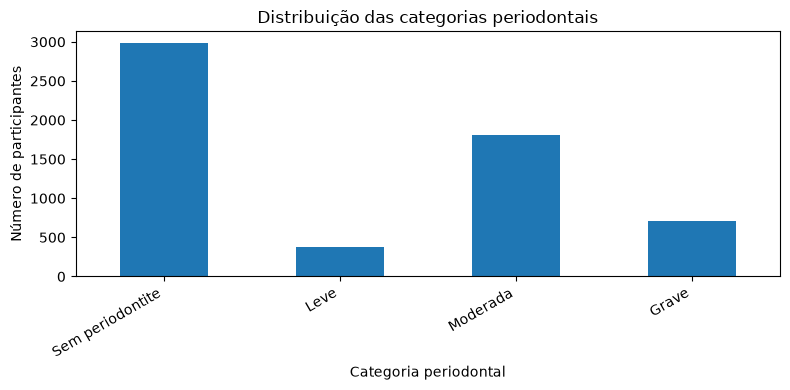

,Número de participantes
periodontite_binaria,
Sem periodontite,2985
Com periodontite,2892


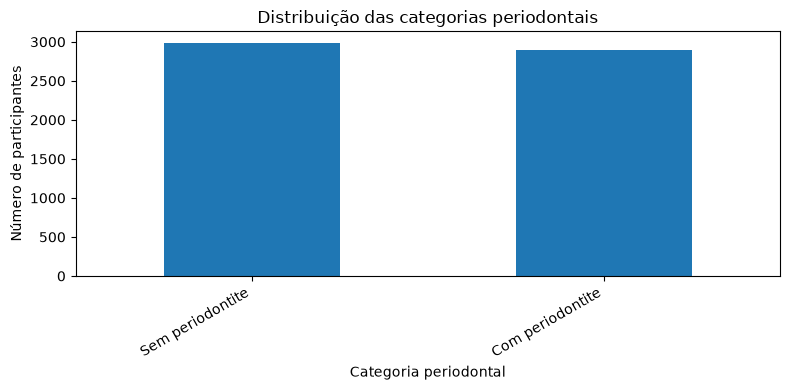

In [18]:
class_order = [
    "Sem periodontite",
    "Leve",
    "Moderada",
    "Grave"
]

class_counts = (
    df_model["periodontite_classe"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

display(class_counts.rename("Número de participantes").to_frame())

class_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Distribuição das categorias periodontais")
plt.xlabel("Categoria periodontal")
plt.ylabel("Número de participantes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


class_counts = (
    df_model["periodontite_binaria"]
    .value_counts()
    .reindex(fill_value=0)
)

display(class_counts.rename("Número de participantes").to_frame())

class_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Distribuição das categorias periodontais")
plt.xlabel("Categoria periodontal")
plt.ylabel("Número de participantes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 4.4 Anotação taxonômica: associação dos códigos aos nomes

Carregaremos o arquivo de anotação taxonômica do NHANES e criaremos uma função para trocar códigos `RSV_genus` por nomes taxonômicos nas visualizações. Quando o gênero não estiver classificado ou o nome não estiver disponível, o rótulo manterá informação suficiente para reconhecer o táxon.


In [19]:
# Carregar a anotação taxonômica local do NHANES
taxonomia = pd.read_csv(
    DATA_DIR / "dada2rsv-taxonomy-annotate.txt",
    sep="\t",
    dtype=str,
    encoding="utf-8-sig"
)

taxonomia.columns = taxonomia.columns.str.strip()

# Manter apenas as anotações correspondentes ao nível de gênero
taxonomia_generos = taxonomia[
    taxonomia["Name"].str.startswith("RSV_genus", na=False)
].copy()

# Criar um dicionário: código RSV_genus -> classificação taxonômica
mapa_taxonomia = dict(
    zip(
        taxonomia_generos["Name"].str.strip(),
        taxonomia_generos["Taxonomy in SILVA v123"].str.strip()
    )
)


# Função para substituir códigos RSV_genus pelo táxon mais específico disponível.
# O arquivo apresenta seis níveis: domínio, filo, classe, ordem, família e gênero.
NOMES_NIVEIS_TAXONOMICOS = ["domínio", "filo", "classe", "ordem", "família", "gênero"]
TERMOS_DESCONHECIDOS = {"", "NA", "NAN", "N/A", "UNKNOWN", "UNCLASSIFIED", "UNCULTURED"}

def rotular_taxons(colunas):
    rotulos = []

    for codigo in colunas:
        classificacao = mapa_taxonomia.get(str(codigo))

        if not classificacao or pd.isna(classificacao):
            rotulos.append(str(codigo))
            continue

        niveis = [nivel.strip() for nivel in classificacao.split(";")]
        nivel_conhecido = None

        for posicao in range(min(len(niveis), len(NOMES_NIVEIS_TAXONOMICOS)) - 1, -1, -1):
            if niveis[posicao].upper() not in TERMOS_DESCONHECIDOS:
                nivel_conhecido = posicao
                break

        if nivel_conhecido is None:
            rotulo = f"Táxon não classificado [{codigo}]"
        else:
            nome = niveis[nivel_conhecido].replace("_", " ").strip()
            categoria = NOMES_NIVEIS_TAXONOMICOS[nivel_conhecido]
            rotulo = nome if categoria == "gênero" else f"{nome} ({categoria})"

        rotulos.append(rotulo)

    # Se rótulos repetirem, acrescenta o código original para distinguir as variáveis.
    contagem = pd.Series(rotulos).value_counts()
    return [
        f"{rotulo} [{codigo}]" if contagem[rotulo] > 1 or "não classificado" in rotulo.lower() else rotulo
        for codigo, rotulo in zip(colunas, rotulos)
    ]

print("Códigos RSV_genus anotados:", len(taxonomia_generos))
print("Exemplos de correspondências:")

display(taxonomia_generos.head(5))

Códigos RSV_genus anotados: 1349
Exemplos de correspondências:


,Name,Taxonomy in SILVA v123
868,RSV_genus1,Bacteria;Acidobacteria;Acidobacteria;Acidobact...
869,RSV_genus2,Bacteria;Acidobacteria;Acidobacteria;Acidobact...
870,RSV_genus3,Bacteria;Acidobacteria;Acidobacteria;Acidobact...
871,RSV_genus4,Bacteria;Acidobacteria;Acidobacteria;Acidobact...
872,RSV_genus5,Bacteria;Acidobacteria;Acidobacteria;Subgroup_...


Participantes por categoria periodontal (multiclasse):


,n
periodontite_classe,
Sem periodontite,2985
Leve,379
Moderada,1804
Grave,709



Participantes por condição periodontal (binária):


,n
periodontite_binaria,
Sem periodontite,2985
Com periodontite,2892



Resultados dos testes de diversidade alfa:


,Desfecho,Índice,Teste,Estatística,p-valor
0,Multiclasse (4 categorias),Shannon,Kruskal–Wallis,458.946,3.757e-99
1,Binário (com/sem periodontite),Shannon,Mann–Whitney U,3103002.500,1.078e-77
2,Multiclasse (4 categorias),Riqueza_observada,Kruskal–Wallis,588.178,3.682e-127
3,Binário (com/sem periodontite),Riqueza_observada,Mann–Whitney U,2883020.500,1.095e-107


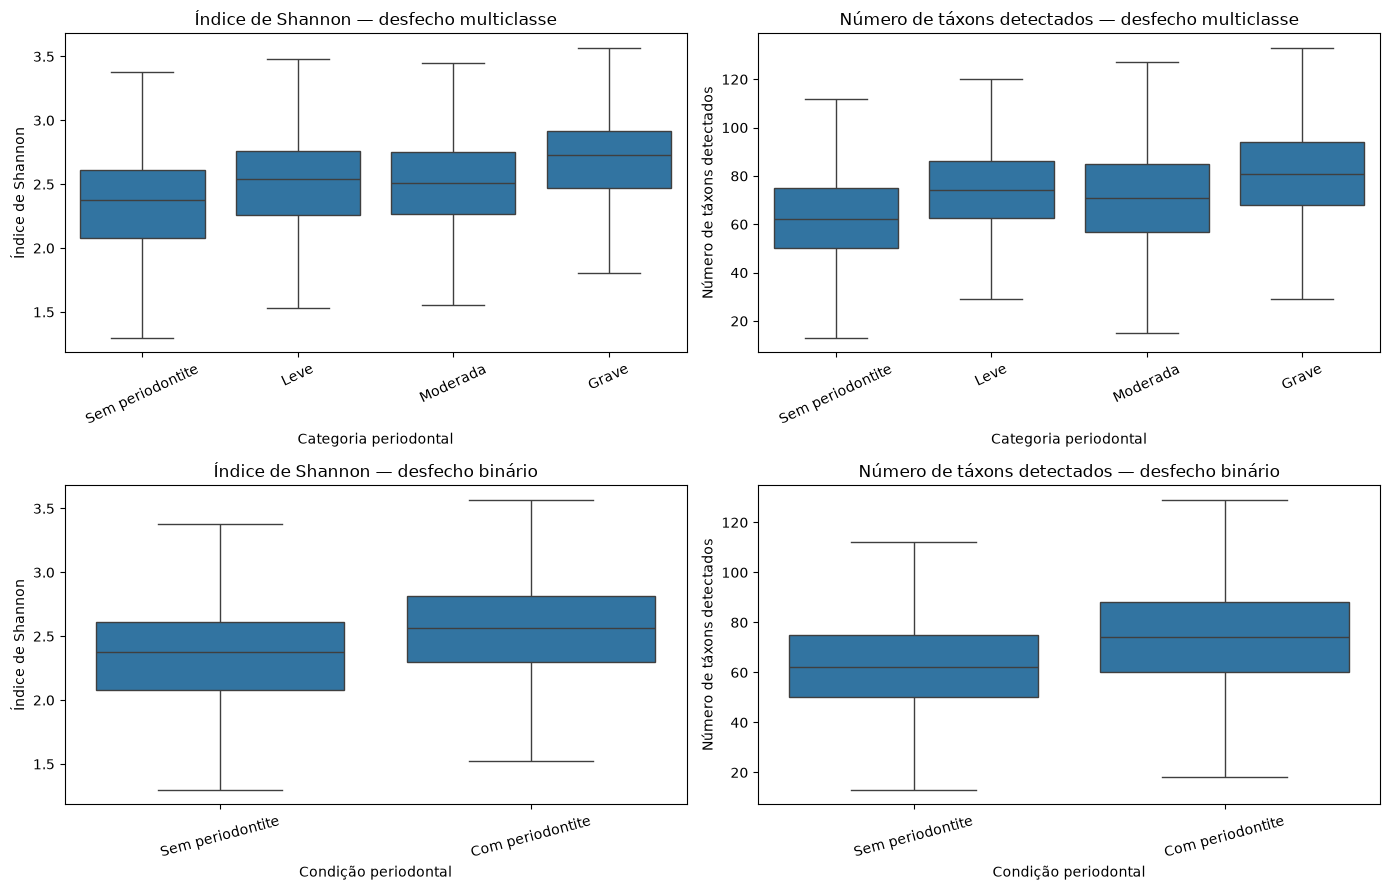

In [20]:
from scipy.stats import kruskal, mannwhitneyu
import seaborn as sns

# A matriz já contém abundâncias relativas por participante.
X_alpha = df_model[microbial_cols].to_numpy(dtype=float)
X_alpha = np.clip(X_alpha, 0, None)

# Shannon: H = -sum(p_i * ln(p_i)); os zeros contribuem com zero.
log_p = np.zeros_like(X_alpha, dtype=float)
mascara_positiva = X_alpha > 0
log_p[mascara_positiva] = np.log(X_alpha[mascara_positiva])
shannon = -(X_alpha * log_p).sum(axis=1)

# Riqueza observada: número de táxons detectados em cada amostra.
riqueza_observada = (X_alpha > 0).sum(axis=1)

df_alpha = df_model[
    ["SEQN", "periodontite_classe", "periodontite_binaria"]
].copy()
df_alpha["Shannon"] = shannon
df_alpha["Riqueza_observada"] = riqueza_observada

ordem_multi_alpha = [
    classe for classe in class_order
    if classe in df_alpha["periodontite_classe"].dropna().unique()
]
ordem_bin_alpha = ["Sem periodontite", "Com periodontite"]

# Tamanho dos grupos em cada forma de classificação.
print("Participantes por categoria periodontal (multiclasse):")
display(
    df_alpha["periodontite_classe"]
    .value_counts()
    .reindex(ordem_multi_alpha)
    .to_frame("n")
)
print("\nParticipantes por condição periodontal (binária):")
display(
    df_alpha["periodontite_binaria"]
    .value_counts()
    .reindex(ordem_bin_alpha)
    .to_frame("n")
)

# Testes globais entre as quatro categorias e entre os dois grupos binários.
resultados_alpha = []
for indice in ["Shannon", "Riqueza_observada"]:
    grupos_multi = [
        df_alpha.loc[
            df_alpha["periodontite_classe"] == classe, indice
        ].dropna().to_numpy()
        for classe in ordem_multi_alpha
    ]
    if len(grupos_multi) >= 2 and all(len(g) > 0 for g in grupos_multi):
        estatistica, p_valor = kruskal(*grupos_multi)
    else:
        estatistica, p_valor = np.nan, np.nan

    grupos_bin = [
        df_alpha.loc[
            df_alpha["periodontite_binaria"] == classe, indice
        ].dropna().to_numpy()
        for classe in ordem_bin_alpha
    ]
    if all(len(g) > 0 for g in grupos_bin):
        estatistica_bin, p_valor_bin = mannwhitneyu(
            grupos_bin[0], grupos_bin[1],
            alternative="two-sided",
            method="asymptotic"
        )
    else:
        estatistica_bin, p_valor_bin = np.nan, np.nan

    resultados_alpha.extend([
        {
            "Desfecho": "Multiclasse (4 categorias)",
            "Índice": indice,
            "Teste": "Kruskal–Wallis",
            "Estatística": estatistica,
            "p-valor": p_valor
        },
        {
            "Desfecho": "Binário (com/sem periodontite)",
            "Índice": indice,
            "Teste": "Mann–Whitney U",
            "Estatística": estatistica_bin,
            "p-valor": p_valor_bin
        }
    ])

tabela_alpha = pd.DataFrame(resultados_alpha)
print("\nResultados dos testes de diversidade alfa:")
display(
    tabela_alpha.style.format({
        "Estatística": "{:.3f}",
        "p-valor": "{:.3e}"
    })
)

# Visualização: primeira linha = quatro categorias; segunda linha = dois grupos.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for coluna, indice in enumerate(["Shannon", "Riqueza_observada"]):
    sns.boxplot(
        data=df_alpha,
        x="periodontite_classe",
        y=indice,
        order=ordem_multi_alpha,
        showfliers=False,
        ax=axes[0, coluna]
    )
    sns.boxplot(
        data=df_alpha,
        x="periodontite_binaria",
        y=indice,
        order=ordem_bin_alpha,
        showfliers=False,
        ax=axes[1, coluna]
    )

    nome_indice = (
        "Índice de Shannon" if indice == "Shannon"
        else "Número de táxons detectados"
    )
    axes[0, coluna].set_title(f"{nome_indice} — desfecho multiclasse")
    axes[1, coluna].set_title(f"{nome_indice} — desfecho binário")
    axes[0, coluna].set_xlabel("Categoria periodontal")
    axes[1, coluna].set_xlabel("Condição periodontal")
    axes[0, coluna].set_ylabel(nome_indice)
    axes[1, coluna].set_ylabel(nome_indice)
    axes[0, coluna].tick_params(axis="x", rotation=25)
    axes[1, coluna].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**Interpretação e implicações biológicas e computacionais — S1.** Esta análise apresenta duas leituras complementares dos mesmos índices de diversidade. Na visão **multiclasse**, podemos observar se existe um padrão entre as categorias sem periodontite, leve, moderada e grave. Na visão **binária**, avaliamos se a distribuição geral da diversidade difere entre participantes com e sem periodontite. O agrupamento binário simplifica a pergunta e reúne os três níveis de doença em um único grupo.

Shannon aumenta quando há maior diversidade e maior equabilidade entre os táxons; a riqueza observada aumenta quando mais táxons são detectados. Uma diferença entre grupos pode ser compatível com alterações ecológicas da comunidade, mas não demonstra que essas alterações sejam causadas pela periodontite. A direção do padrão deve ser descrita a partir das medianas e distribuições efetivamente observadas, sem pressupor que a diversidade necessariamente diminua ou aumente com a gravidade.

O Kruskal–Wallis testa se pelo menos uma das quatro distribuições difere; o Mann–Whitney U compara as distribuições dos dois grupos binários. Os testes não identificam, por si só, quais pares de categorias diferem. Para essa pergunta seriam necessários testes pós-hoc apropriados. Os p-valores também não quantificam a magnitude da diferença.

Computacionalmente, esta etapa caracteriza a estrutura global dos dados antes da classificação supervisionada. Diferenças de diversidade podem coexistir com grande sobreposição entre indivíduos e com capacidade preditiva limitada. A riqueza observada é sensível à profundidade de sequenciamento e ao limiar de detecção; como não foi aplicada rarefação ou padronização explícita da profundidade nesta etapa, diferenças na riqueza devem ser interpretadas com cautela.

## 5. Modelo base: CLR + XGBoost

Nesta seção treinamos o primeiro classificador para o desfecho binário (**sem periodontite × com periodontite**). Seguimos o mesmo fluxo da aula *Machine Learning e Metagenômica* (`aula_metagenomica_ml.ipynb`), que trata de um problema análogo (abundâncias de gêneros obtidas por 16S rRNA para distinguir pacientes de controles):

1. abundância relativa → transformação **CLR** (*centered log-ratio*);
2. divisão estratificada em treino e teste (`train_test_split`);
3. classificador **XGBoost** com os parâmetros padrão;
4. avaliação com matriz de confusão, precisão, recall, F1 e curva ROC;
5. importância dos atributos (`feature_importances_`).

### Protocolo de avaliação

Uma única divisão treino/teste pode, por acaso, ser mais fácil ou mais difícil que o normal. Para que o resultado não dependa disso, **repetimos a divisão com 10 sementes aleatórias** (*seeds*) e reportamos **média ± desvio padrão** de cada métrica. A semente 42 está entre elas, o que permite comparar diretamente com outras análises que usem a mesma divisão (`test_size=0.25`, `random_state=42`, estratificada).

Como referência, avaliamos também um `DummyClassifier`, que sempre prevê a classe mais frequente do treino. Ele mostra o desempenho esperado **sem nenhuma informação do microbioma**; um modelo útil precisa superá-lo com folga.

> **Desvios em relação às aulas** (pequenos e intencionais):
> - a repetição com várias sementes é uma extensão da ideia do `cross_val_score` (aulas 01 e 07), aplicada à divisão treino/teste;
> - o `DummyClassifier` não aparece nas aulas e é usado apenas como linha de base;
> - a importância dos atributos é a média dos 10 modelos (um por semente), em vez de um único modelo treinado com todos os dados.

### 5.1 Transformação CLR

As abundâncias relativas são composicionais: somam 1 em cada amostra, então o aumento de um táxon obriga a redução aparente dos outros. A CLR divide cada abundância pela média geométrica da amostra e aplica o logaritmo, levando os dados para uma escala em que essa restrição deixa de distorcer as comparações.

Usamos a mesma função da aula de metagenômica. Como o logaritmo de zero não existe, valores menores que $10^{-6}$ são substituídos por $10^{-6}$ antes da transformação. A CLR é calculada **amostra por amostra**, sem usar informação de outros participantes, portanto pode ser aplicada antes da divisão treino/teste sem vazamento de informação.

In [21]:
# Transformação CLR — mesma função da aula de metagenômica.
# (Na aula usa-se X.applymap(lambda x: x if x > 1e-6 else 1e-6); o applymap foi
# removido no pandas 3, e X.clip(lower=1e-6) faz exatamente a mesma substituição.)
def clr(X):
    # Aplica a transformação CLR a um DataFrame (amostras nas linhas).
    X = X.clip(lower=1e-6)                   # evita log(0)
    gm = np.exp(np.mean(np.log(X), axis=1))  # média geométrica por linha
    return np.log(X.div(gm, axis=0))


X_clr = clr(X)
X_clr.index = df_model["SEQN"]

# Desfecho binário em 0/1, como o map_target da aula
mapa_desfecho = {"Sem periodontite": 0, "Com periodontite": 1}
y_bin01 = y_bin.map(mapa_desfecho)
y_bin01.index = X_clr.index

if y_bin01.isna().any():
    raise ValueError("Há rótulos binários fora de 'Sem periodontite'/'Com periodontite'.")

print("Matriz CLR:", X_clr.shape)
print("Distribuição do desfecho (0 = sem, 1 = com periodontite):")
print(y_bin01.value_counts().sort_index())

Matriz CLR: (5877, 1349)
Distribuição do desfecho (0 = sem, 1 = com periodontite):
periodontite_binaria
0    2985
1    2892
Name: count, dtype: int64


### 5.2 Avaliação repetida com 10 sementes

Para cada semente: dividimos os dados (75% treino, 25% teste, estratificado pelo desfecho), treinamos o modelo **apenas no treino** e calculamos as métricas **apenas no teste**. Guardamos também as predições da semente 42 para os gráficos e as importâncias de cada modelo XGBoost.

O treinamento do XGBoost nas 10 sementes leva alguns minutos.

In [22]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
)
from sklearn.model_selection import train_test_split
import xgboost as xgb

SEMENTES = [42, 1, 2, 3, 4, 5, 6, 7, 8, 9]
SEMENTE_REFERENCIA = 42
TAMANHO_TESTE = 0.25

modelos_base = {
    "Dummy (classe mais frequente)": lambda semente: DummyClassifier(strategy="most_frequent"),
    "XGBoost": lambda semente: xgb.XGBClassifier(random_state=semente, n_jobs=-1),
}


def avaliar_com_sementes(criar_modelo, X, y, sementes):
    # Treina e avalia o modelo em uma divisão treino/teste por semente.
    linhas, importancias, referencia = [], [], None
    for semente in sementes:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=TAMANHO_TESTE, random_state=semente, stratify=y
        )
        modelo = criar_modelo(semente).fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
        # Pontuação usada na AUC: probabilidade da classe 1 ou, para modelos sem
        # predict_proba (ex.: SGDClassifier da aula 03), a distância à fronteira.
        if hasattr(modelo, "predict_proba"):
            y_prob = modelo.predict_proba(X_test)[:, 1]
        else:
            y_prob = modelo.decision_function(X_test)
        linhas.append({
            "semente": semente,
            "acurácia": accuracy_score(y_test, y_pred),
            "precisão": precision_score(y_test, y_pred, zero_division=0),
            "recall": recall_score(y_test, y_pred),
            "F1": f1_score(y_test, y_pred),
            "AUC": roc_auc_score(y_test, y_prob),
        })
        if hasattr(modelo, "feature_importances_"):
            importancias.append(pd.Series(modelo.feature_importances_, index=X.columns))
        if semente == SEMENTE_REFERENCIA:
            referencia = {"modelo": modelo, "X_test": X_test, "y_test": y_test,
                          "y_pred": y_pred, "y_prob": y_prob}
    return pd.DataFrame(linhas), importancias, referencia


resultados_base = {}
for nome, criar in modelos_base.items():
    print(f"Avaliando {nome} ...")
    resultados_base[nome] = avaliar_com_sementes(criar, X_clr, y_bin01, SEMENTES)

metricas_por_semente = pd.concat(
    {nome: r[0] for nome, r in resultados_base.items()}, names=["modelo"]
).reset_index(level=0)

resumo_base = (
    metricas_por_semente.drop(columns="semente")
    .groupby("modelo")
    .agg(["mean", "std"])
)
display(resumo_base.round(3))

Avaliando Dummy (classe mais frequente) ...


Avaliando XGBoost ...


acurácia       precisão        recall         \
                                  mean   std     mean    std   mean    std   
modelo                                                                       
Dummy (classe mais frequente)    0.508  0.00    0.000  0.000  0.000  0.000   
XGBoost                          0.709  0.01    0.717  0.012  0.674  0.021   

                                  F1           AUC         
                                mean    std   mean    std  
modelo                                                     
Dummy (classe mais frequente)  0.000  0.000  0.500  0.000  
XGBoost                        0.694  0.013  0.777  0.011

A tabela mostra, para cada métrica, a **média** e o **desvio padrão** nas 10 divisões. O desvio padrão indica o quanto o resultado varia só por causa de quais participantes caíram no teste.

- **Acurácia:** proporção de acertos.
- **Precisão:** entre os classificados como *com periodontite*, quantos realmente têm.
- **Recall (sensibilidade):** entre os que têm periodontite, quantos o modelo encontrou.
- **F1:** média harmônica entre precisão e recall.
- **AUC:** área sob a curva ROC. Mede a capacidade de ordenar os participantes pelo risco, independentemente do limiar de decisão: 0,5 equivale ao acaso e 1,0 à separação perfeita.

O `DummyClassifier` não usa os dados do microbioma, por isso sua AUC é 0,5 e sua acurácia é a proporção da classe mais frequente.

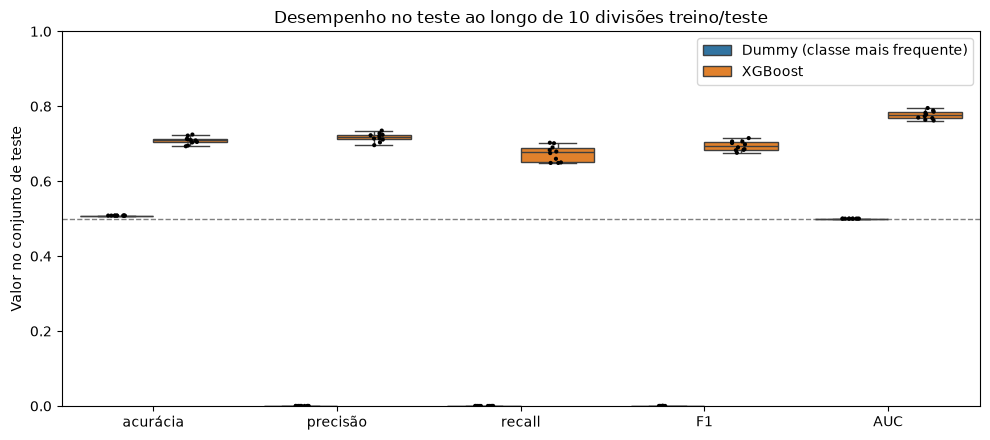

In [23]:
# Distribuição das métricas nas 10 sementes
metricas_longo = metricas_por_semente.melt(
    id_vars=["modelo", "semente"], var_name="métrica", value_name="valor"
)

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=metricas_longo, x="métrica", y="valor", hue="modelo", showfliers=False)
sns.stripplot(data=metricas_longo, x="métrica", y="valor", hue="modelo",
              dodge=True, palette=["black", "black"], size=3, legend=False)
plt.axhline(0.5, color="grey", linestyle="--", linewidth=1)
plt.ylim(0, 1)
plt.title("Desempenho no teste ao longo de 10 divisões treino/teste")
plt.ylabel("Valor no conjunto de teste")
plt.xlabel("")
plt.legend(title="")
plt.tight_layout()
plt.show()

### 5.3 Matriz de confusão e curva ROC (semente 42)

Os gráficos abaixo detalham uma das 10 divisões, a da semente 42, no mesmo formato da aula de metagenômica.

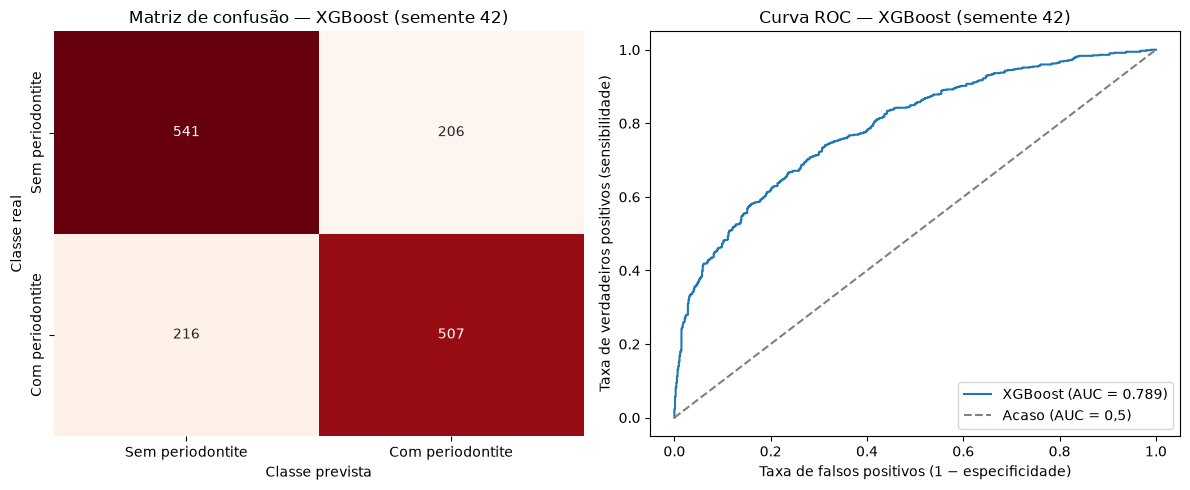

In [24]:
ref = resultados_base["XGBoost"][2]
nomes_classes = ["Sem periodontite", "Com periodontite"]

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

# Matriz de confusão
matriz = confusion_matrix(ref["y_test"], ref["y_pred"])
sns.heatmap(matriz, annot=True, fmt=".0f", cmap="Reds", cbar=False,
            xticklabels=nomes_classes, yticklabels=nomes_classes, ax=eixos[0])
eixos[0].set_title("Matriz de confusão — XGBoost (semente 42)")
eixos[0].set_xlabel("Classe prevista")
eixos[0].set_ylabel("Classe real")

# Curva ROC
fpr, tpr, _ = roc_curve(ref["y_test"], ref["y_prob"])
auc_ref = roc_auc_score(ref["y_test"], ref["y_prob"])
eixos[1].plot(fpr, tpr, label=f"XGBoost (AUC = {auc_ref:.3f})")
eixos[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Acaso (AUC = 0,5)")
eixos[1].set_xlabel("Taxa de falsos positivos (1 − especificidade)")
eixos[1].set_ylabel("Taxa de verdadeiros positivos (sensibilidade)")
eixos[1].set_title("Curva ROC — XGBoost (semente 42)")
eixos[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### 5.4 Gêneros mais importantes para o modelo

A importância (`feature_importances_`) indica o quanto cada gênero contribuiu para as divisões das árvores do XGBoost. Para não depender de uma única divisão, usamos a **média das importâncias dos 10 modelos**; a barra de erro mostra o desvio padrão entre eles.

Importância alta não significa que o gênero cause periodontite, nem indica a direção do efeito (se é mais ou menos abundante na doença). Ela apenas mostra quais atributos o modelo mais usou para separar as classes.

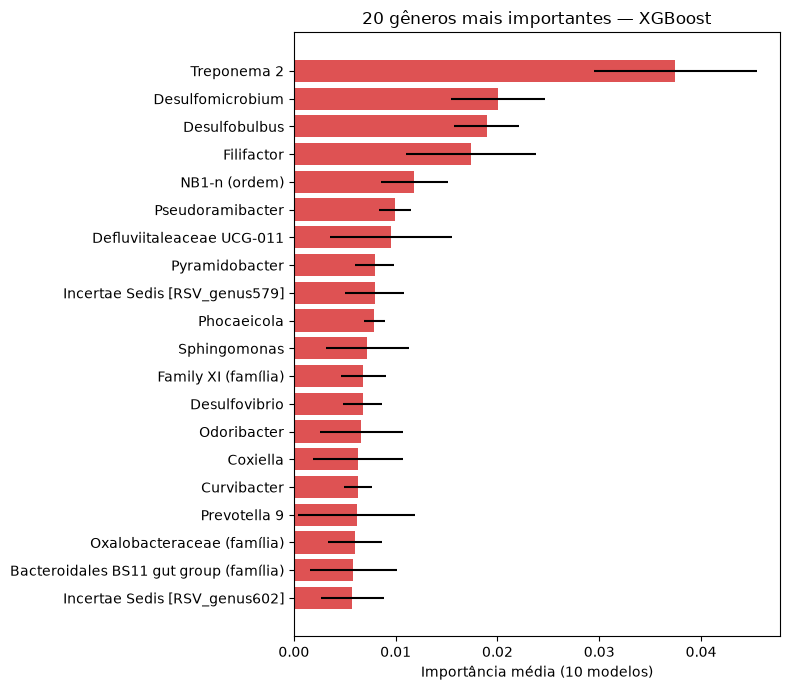

,média,desvio
Treponema 2,0.0375,0.0080
Desulfomicrobium,0.0201,0.0047
Desulfobulbus,0.0189,0.0032
Filifactor,0.0174,0.0064
NB1-n (ordem),0.0118,0.0033
Pseudoramibacter,0.0099,0.0015
Defluviitaleaceae UCG-011,0.0095,0.0060
Pyramidobacter,0.0079,0.0019
Incertae Sedis [RSV_genus579],0.0079,0.0029
Phocaeicola,0.0079,0.0010


In [25]:
importancias_xgb = pd.concat(resultados_base["XGBoost"][1], axis=1)
resumo_importancia = pd.DataFrame({
    "média": importancias_xgb.mean(axis=1),
    "desvio": importancias_xgb.std(axis=1),
}).sort_values("média", ascending=False)

top20 = resumo_importancia.head(20).copy()
top20.index = rotular_taxons(top20.index)

plt.figure(figsize=(8, 7))
plt.barh(top20.index[::-1], top20["média"][::-1], xerr=top20["desvio"][::-1], color="tab:red", alpha=0.8)
plt.xlabel("Importância média (10 modelos)")
plt.title("20 gêneros mais importantes — XGBoost")
plt.tight_layout()
plt.show()

display(top20.round(4))

## 6. Comparação de classificadores

O XGBoost é só um dos algoritmos possíveis. Aqui comparamos, **no mesmo protocolo da seção 5** (mesma matriz CLR, mesmas 10 sementes, mesmas métricas), os classificadores trabalhados nas aulas:

| Classificador | Aula de referência |
|---|---|
| `LogisticRegression` | aulas 03, 05 e 07 |
| `KNeighborsClassifier` (kNN) | aulas 03 e 07 |
| `SGDClassifier` | aulas 03 e 07 |
| `DecisionTreeClassifier` | aulas 07 e 12 |
| `RandomForestClassifier` | aula 16 |
| `XGBClassifier` | aula de metagenômica (resultado da seção 5) |

Todos usam os **parâmetros padrão**; o ajuste de hiperparâmetros fica para uma seção posterior. A única exceção é o `max_iter=1000` da regressão logística, necessário para o algoritmo de otimização convergir com 1.349 atributos.

Como as 10 divisões são **as mesmas para todos os modelos**, as diferenças entre eles não se devem a terem sido testados em participantes diferentes.

**Padronização.** LogReg, kNN e SGD dependem da escala dos atributos (a distância do kNN e o gradiente da LogReg e do SGD mudam quando um atributo tem valores muito maiores que outro). Por isso, como na aula 03, eles recebem um `StandardScaler` ajustado **somente no treino**. Árvores, Random Forest e XGBoost não dependem da escala e usam a matriz CLR diretamente.

> **Desvio em relação às aulas:** o `StandardScaler` e o modelo são encadeados com `make_pipeline`, que não aparece nas aulas. O resultado é o mesmo do código da aula 03 (`scaler.fit(X_train)` e depois `transform` no treino e no teste), mas garante automaticamente que o teste nunca é usado para calcular média e desvio do scaler em nenhuma das 10 sementes.

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

modelos_comparacao = {
    "Regressão logística": lambda semente: make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=semente)
    ),
    "kNN": lambda semente: make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "SGD": lambda semente: make_pipeline(StandardScaler(), SGDClassifier(random_state=semente)),
    "Árvore de decisão": lambda semente: DecisionTreeClassifier(random_state=semente),
    "Random Forest": lambda semente: RandomForestClassifier(random_state=semente, n_jobs=-1),
}

resultados_comparacao = {}
for nome, criar in modelos_comparacao.items():
    print(f"Avaliando {nome} ...")
    resultados_comparacao[nome] = avaliar_com_sementes(criar, X_clr, y_bin01, SEMENTES)

# Junta com os resultados da seção 5 (Dummy e XGBoost)
todos_resultados = {**resultados_base, **resultados_comparacao}

metricas_todos = pd.concat(
    {nome: r[0] for nome, r in todos_resultados.items()}, names=["modelo"]
).reset_index(level=0)

resumo_todos = (
    metricas_todos.drop(columns="semente")
    .groupby("modelo")
    .agg(["mean", "std"])
    .sort_values(("AUC", "mean"), ascending=False)
)
display(resumo_todos.round(3))

Avaliando Regressão logística ...


Avaliando kNN ...


Avaliando SGD ...


Avaliando Árvore de decisão ...


Avaliando Random Forest ...


acurácia        precisão        recall         \
                                  mean    std     mean    std   mean    std   
modelo                                                                        
XGBoost                          0.709  0.010    0.717  0.012  0.674  0.021   
Random Forest                    0.701  0.007    0.718  0.010  0.644  0.018   
Regressão logística              0.686  0.013    0.691  0.012  0.653  0.023   
kNN                              0.647  0.013    0.664  0.015  0.572  0.017   
SGD                              0.630  0.070    0.626  0.073  0.625  0.066   
Árvore de decisão                0.615  0.013    0.609  0.013  0.604  0.022   
Dummy (classe mais frequente)    0.508  0.000    0.000  0.000  0.000  0.000   

                                  F1           AUC         
                                mean    std   mean    std  
modelo                                                     
XGBoost                        0.694  0.013  0.777  0.011  
Random Forest                  0.679  0.010  0.759  0.008  
Regressão logística            0.671  0.017  0.727  0.014  
kNN                            0.614  0.015  0.689  0.013  
SGD                            0.625  0.066  0.663  0.083  
Árvore de decisão              0.607  0.015  0.615  0.013  
Dummy (classe mais frequente)  0.000  0.000  0.500  0.000

A tabela está ordenada pela AUC média. Como a AUC não depende do limiar de decisão, ela é a métrica principal para comparar os modelos; acurácia, precisão, recall e F1 dependem do limiar padrão de 0,5.

O gráfico abaixo mostra a AUC de cada modelo em cada semente. As linhas cinzas ligam os resultados de **uma mesma divisão** treino/teste, o que ajuda a ver se a ordem entre os modelos se mantém em todas as divisões ou se muda conforme a semente.

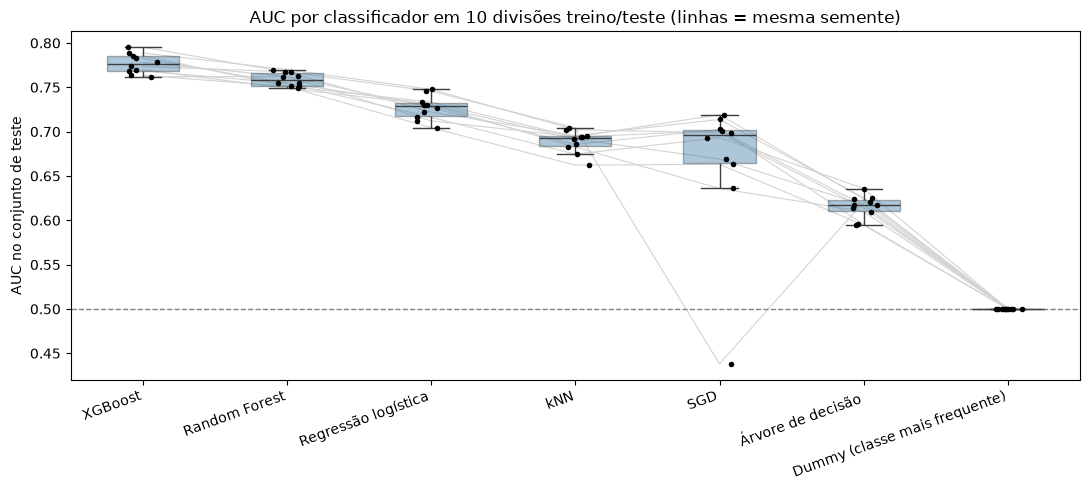

,sementes em que teve a maior AUC
XGBoost,9
Random Forest,1


In [27]:
ordem_modelos = list(resumo_todos.index)
auc_por_semente = metricas_todos.pivot(index="semente", columns="modelo", values="AUC")[ordem_modelos]

fig, ax = plt.subplots(figsize=(11, 5))
for _, linha in auc_por_semente.iterrows():
    ax.plot(range(len(ordem_modelos)), linha.values, color="lightgrey", linewidth=0.8, zorder=1)
sns.boxplot(data=auc_por_semente, ax=ax, color="tab:blue", width=0.5, boxprops={"alpha": 0.4}, showfliers=False, zorder=2)
sns.stripplot(data=auc_por_semente, ax=ax, color="black", size=4, zorder=3)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("AUC no conjunto de teste")
ax.set_xlabel("")
ax.set_title("AUC por classificador em 10 divisões treino/teste (linhas = mesma semente)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Em quantas das 10 sementes cada modelo teve a maior AUC
vencedor = auc_por_semente.drop(columns="Dummy (classe mais frequente)").idxmax(axis=1)
display(vencedor.value_counts().rename("sementes em que teve a maior AUC").to_frame())

### 6.1 Curvas ROC na semente 42

Para visualizar as diferenças, sobrepomos as curvas ROC de todos os classificadores na divisão da semente 42.

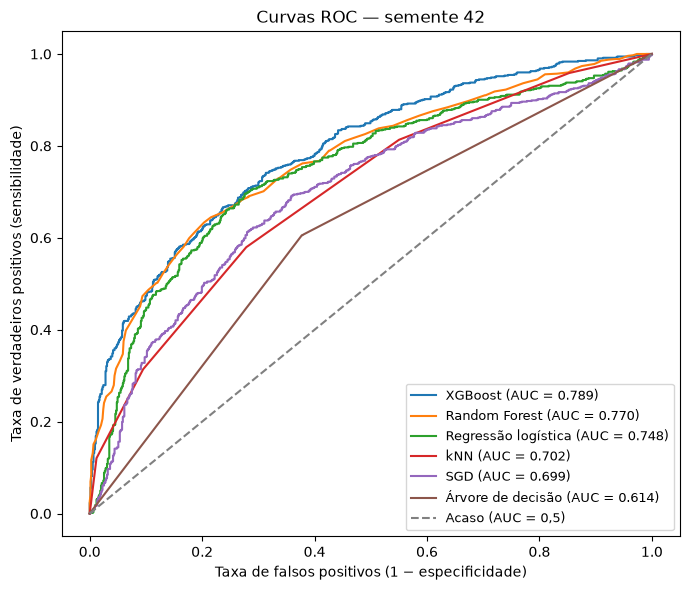

In [28]:
fig, ax = plt.subplots(figsize=(7, 6))
for nome in ordem_modelos:
    if nome.startswith("Dummy"):
        continue
    ref = todos_resultados[nome][2]
    fpr, tpr, _ = roc_curve(ref["y_test"], ref["y_prob"])
    auc_ref = roc_auc_score(ref["y_test"], ref["y_prob"])
    ax.plot(fpr, tpr, label=f"{nome} (AUC = {auc_ref:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Acaso (AUC = 0,5)")
ax.set_xlabel("Taxa de falsos positivos (1 − especificidade)")
ax.set_ylabel("Taxa de verdadeiros positivos (sensibilidade)")
ax.set_title("Curvas ROC — semente 42")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## Salvar os resultados para a demonstração

Quando o modelo final estiver pronto, descomente a célula abaixo e ajuste os nomes das variáveis. Ela grava a pasta `resultados/`, que é lida pelo app de demonstração (`app.py`).

- `modelo_final`: o modelo treinado (de preferência um `Pipeline`, com o pré-processamento incluído);
- `X_teste` / `y_teste`: o conjunto de teste, com o `SEQN` como índice e `y_teste` com 0 (sem periodontite) ou 1 (periodontite);
- `metricas`: dicionário com as métricas no teste;
- `figuras`: dicionário `nome -> figura do matplotlib`;
- `rotulos_atributos`: dicionário `código RSV -> nome do gênero` (para mostrar nomes legíveis no app).

In [29]:
# from resultados import salvar_resultados
#
# salvar_resultados(
#     modelo=modelo_final,
#     X_teste=X_teste,
#     y_teste=y_teste,
#     metricas={"acuracia_balanceada": ..., "auc_roc": ...},
#     figuras={"curva_roc": fig_roc, "matriz_confusao": fig_cm},
#     rotulos_atributos=rotulos_atributos,
# )